# Multi-Class Classification & Predictive Maintenance Using Machine Learning

This repository/notebook addresses two distinct, real-world engineering classification problems using Supervised Machine Learning techniques: **Steel Plates Faults Detection** and **Predictive Maintenance for Rotary Machinery**.

---

## Project Structure & Problem Statements

### 1. Task 1: Steel Plates Faults Diagnostics
* **Problem Statement:** Detect and classify 7 different types of faults in steel plates based on 27 geometric and textural features of the faults.
* **Dataset:** Steel Plates Faults dataset (UCI ID: 198).
* **Target Labels:** Multi-label target transformed into a 1D multi-class problem containing:
  * `Pastry`, `Z_Scratch`, `K_Scratch`, `Stains`, `Dirtiness`, `Bumps`, and `Other_Faults`.
* **Methodology:**
  * Evaluation of **Gaussian Naive Bayes** under two prior distribution strategies: **Equal Priors** vs **Class Weighted Priors**.
  * Comparison of **Support Vector Classifiers (SVC)** using different multi-class strategies (One-Vs-One vs One-Vs-Rest).

### 2. Task 2: Predictive Maintenance of Manufacturing Equipment
* **Problem Statement:** Predict failure modes of machines based on operational parameters to prevent sudden breakdowns.
* **Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI ID: 601).
* **Features:** Operating temperatures, rotational speed, torque, tool wear, and machine type.
* **Targets:** Different failure modes including:
  * `Machine failure`, `TWF` (Tool Wear Failure), `HDF` (Heat Dissipation Failure), `PWF` (Power Failure), `OSF` (Overstrain Failure), and `RNF` (Random Failures).
* **Methodology:**
  * Data encoding (One-Hot Encoding) & Standard Scaling.
  * Hyperparameter tuning of **Support Vector Machines (SVM)** across varying regularization values ($C \in \{0.1, 1, 10, 100\}$) and kernels (**Linear (Poly degree 1)**, **Quadratic (Poly degree 2)**, and **RBF**).

In [4]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo


In [5]:
##########TASK1##############

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

In [7]:
steel = fetch_ucirepo(id=198)
X = steel.data.features
y = steel.data.targets

In [8]:
df_steel = pd.DataFrame(X, columns=steel.feature_names)
df_steel = pd.concat([df_steel, y], axis=1)
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", list(y.columns))
print("\nNumber of samples per class:")
print(y.sum())
y.head()

Input shape: (1941, 27)
Target shape: (1941, 7)
Class names: ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

Number of samples per class:
Pastry          158
Z_Scratch       190
K_Scratch       391
Stains           72
Dirtiness        55
Bumps           402
Other_Faults    673
dtype: int64


,Pastry,Z_Scratch,K_Scratch,Stains,Dirtiness,Bumps,Other_Faults
0,1,0,0,0,0,0,0
1,1,0,0,0,0,0,0
2,1,0,0,0,0,0,0
3,1,0,0,0,0,0,0
4,1,0,0,0,0,0,0


In [34]:
# Explicitly fetch/restore the Steel Plates dataset for Task 1 to avoid global namespace override
steel_data_t1 = fetch_ucirepo(id=198)
X_steel_t1 = steel_data_t1.data.features
y_steel_t1 = steel_data_t1.data.targets

X_train_t1, X_test_t1, y_train_t1, y_test_t1 = train_test_split(
    X_steel_t1,
    y_steel_t1,
    test_size=0.30,
    random_state=0,
    stratify=y_steel_t1
)

print("Training samples (Task 1):", X_train_t1.shape[0])
print("Testing samples (Task 1):", X_test_t1.shape[0])

Training samples (Task 1): 1358
Testing samples (Task 1): 583


In [35]:
scaler_nb = StandardScaler()
X_train_nb_scaled = scaler_nb.fit_transform(X_train_t1)
X_test_nb_scaled = scaler_nb.transform(X_test_t1)

In [36]:
priors1 = [1/7,1/7,1/7,1/7,1/7,1/7,1/7]
nb_model1 = GaussianNB(priors=priors1)

y_train_1d_t1 = y_train_t1.idxmax(axis=1)

nb_model1.fit(X_train_nb_scaled, y_train_1d_t1)

priors2 = [158/1941, 190/1941, 391/1941, 72/1941, 55/1941, 402/1941, 673/1941]
nb_model2 = GaussianNB(priors=priors2)
nb_model2.fit(X_train_nb_scaled, y_train_1d_t1)

GaussianNB(priors=[0.08140133951571354, 0.09788768675940238,
                   0.20144255538382277, 0.03709428129829984,
                   0.02833590932509016, 0.2071097372488408,
                   0.3467284904688305])

In [37]:
nb_model1.fit(X_train_nb_scaled, y_train_1d_t1)
y_pred_nb1 = nb_model1.predict(X_test_nb_scaled)

nb_model2.fit(X_train_nb_scaled, y_train_1d_t1)
y_pred_nb2 = nb_model2.predict(X_test_nb_scaled)

In [38]:
# Convert y_test from 2D multi-label to 1D multiclass labels
y_test_1d_t1 = y_test_t1.idxmax(axis=1)

accuracy_nb1 = accuracy_score(y_test_1d_t1, y_pred_nb1)
conf_mat_nb1 = confusion_matrix(y_test_1d_t1, y_pred_nb1)
accuracy_nb2 = accuracy_score(y_test_1d_t1, y_pred_nb2)
conf_mat_nb2 = confusion_matrix(y_test_1d_t1, y_pred_nb2)

report_nb1 = classification_report(
    y_test_1d_t1,
    y_pred_nb1,
    target_names=list(y_test_t1.columns),
    zero_division=0,
)

report_nb2 = classification_report(
    y_test_1d_t1,
    y_pred_nb2,
    target_names=list(y_test_t1.columns),
    zero_division=0,
)

print("Gaussian Naive Bayes — Steel dataset")
print(f"Test accuracy Equal priors: {accuracy_nb1:.4f} ({accuracy_nb1 * 100:.2f}%)")
print(f"Test accuracy Class weighted priors: {accuracy_nb2:.4f} ({accuracy_nb2 * 100:.2f}%)")
print("\nConfusion Matrix (Equal Priors):")
print(conf_mat_nb1)
print("\nConfusion Matrix (Weighted Priors):")
print(conf_mat_nb2)
print("\nClassification Report (Equal Priors):")
print(report_nb1)
print("\nClassification Report (Weighted Priors):")
print(report_nb2)

Gaussian Naive Bayes — Steel dataset
Test accuracy Equal priors: 0.5883 (58.83%)
Test accuracy Class weighted priors: 0.5952 (59.52%)

Confusion Matrix (Equal Priors):
[[ 86   8   3   2  20   1   1]
 [  3  11   0   0   3   0   0]
 [  1   0 105   8   3   0   0]
 [ 54  15  33  47  47   3   3]
 [  6   1   3   3  27   1   6]
 [  0   0   0   0   0  22   0]
 [  4   3   2   1   2   0  45]]

Confusion Matrix (Weighted Priors):
[[ 90   8   3   2  16   1   1]
 [  3  12   0   0   2   0   0]
 [  1   0 106   8   2   0   0]
 [ 58  17  34  44  42   3   4]
 [  6   2   4   3  25   1   6]
 [  0   0   0   0   0  22   0]
 [  2   3   2   1   1   0  48]]

Classification Report (Equal Priors):
              precision    recall  f1-score   support

      Pastry       0.56      0.71      0.63       121
   Z_Scratch       0.29      0.65      0.40        17
   K_Scratch       0.72      0.90      0.80       117
      Stains       0.77      0.23      0.36       202
   Dirtiness       0.26      0.57      0.36      

In [40]:
# Fix: Use the correct isolated variables for Task 1 (Steel dataset)
# and use scaled features since SVM is highly scale-sensitive
classifier_poly1 = SVC(kernel='poly', degree=1, decision_function_shape='ovo')
classifier_poly1.fit(X_train_nb_scaled, y_train_1d_t1)

classifier_poly2 = SVC(kernel='poly', degree=2, decision_function_shape='ovr')
classifier_poly2.fit(X_train_nb_scaled, y_train_1d_t1)

SVC(degree=2, kernel='poly')

In [42]:
# Fix: Use the correct isolated scaled test variables for Task 1
y_pred_poly1 = classifier_poly1.predict(X_test_nb_scaled)
accuracy_poly1 = accuracy_score(y_test_1d_t1, y_pred_poly1)

y_pred_poly2 = classifier_poly2.predict(X_test_nb_scaled)
accuracy_poly2 = accuracy_score(y_test_1d_t1, y_pred_poly2)

print(f"Polynomial kernel (degree=1) — test accuracy (OVO): {accuracy_poly1:.3f}")
print(f"Polynomial kernel (degree=2) — test accuracy (OVR): {accuracy_poly2:.3f}")
print("\nConfusion matrix ovo:\n", confusion_matrix(y_test_1d_t1, y_pred_poly1))
print("\nConfusion matrix ovr:\n", confusion_matrix(y_test_1d_t1, y_pred_poly2))

Polynomial kernel (degree=1) — test accuracy (OVO): 0.715
Polynomial kernel (degree=2) — test accuracy (OVR): 0.732

Confusion matrix ovo:
 [[ 73   0   0  46   1   0   1]
 [  0   2   0  14   1   0   0]
 [  2   0 106   9   0   0   0]
 [ 32   1   6 154   5   1   3]
 [  9   0   2  17  13   0   6]
 [  0   0   0   0   0  22   0]
 [  4   0   0   6   0   0  47]]

Confusion matrix ovr:
 [[ 78   0   0  42   0   0   1]
 [  0   7   0   9   1   0   0]
 [  2   0 104  10   0   0   1]
 [ 31   2   1 159   2   1   6]
 [  7   0   0  21  12   0   7]
 [  0   0   0   0   0  22   0]
 [  1   0   1  10   0   0  45]]


In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Correcting Task 1: Fit and predict SVM using scaled features for better performance
classifier_poly1_scaled = SVC(kernel='poly', degree=1, decision_function_shape='ovo')
classifier_poly1_scaled.fit(X_train_nb_scaled, y_train_1d_t1)

classifier_poly2_scaled = SVC(kernel='poly', degree=2, decision_function_shape='ovr')
classifier_poly2_scaled.fit(X_train_nb_scaled, y_train_1d_t1)

y_pred_poly1_scaled = classifier_poly1_scaled.predict(X_test_nb_scaled)
y_pred_poly2_scaled = classifier_poly2_scaled.predict(X_test_nb_scaled)

print(f"Scaled SVC Polynomial kernel (degree=1, OVO) test accuracy: {accuracy_score(y_test_1d_t1, y_pred_poly1_scaled):.4f}")
print(f"Scaled SVC Polynomial kernel (degree=2, OVR) test accuracy: {accuracy_score(y_test_1d_t1, y_pred_poly2_scaled):.4f}")

Scaled SVC Polynomial kernel (degree=1, OVO) test accuracy: 0.7153
Scaled SVC Polynomial kernel (degree=2, OVR) test accuracy: 0.7324


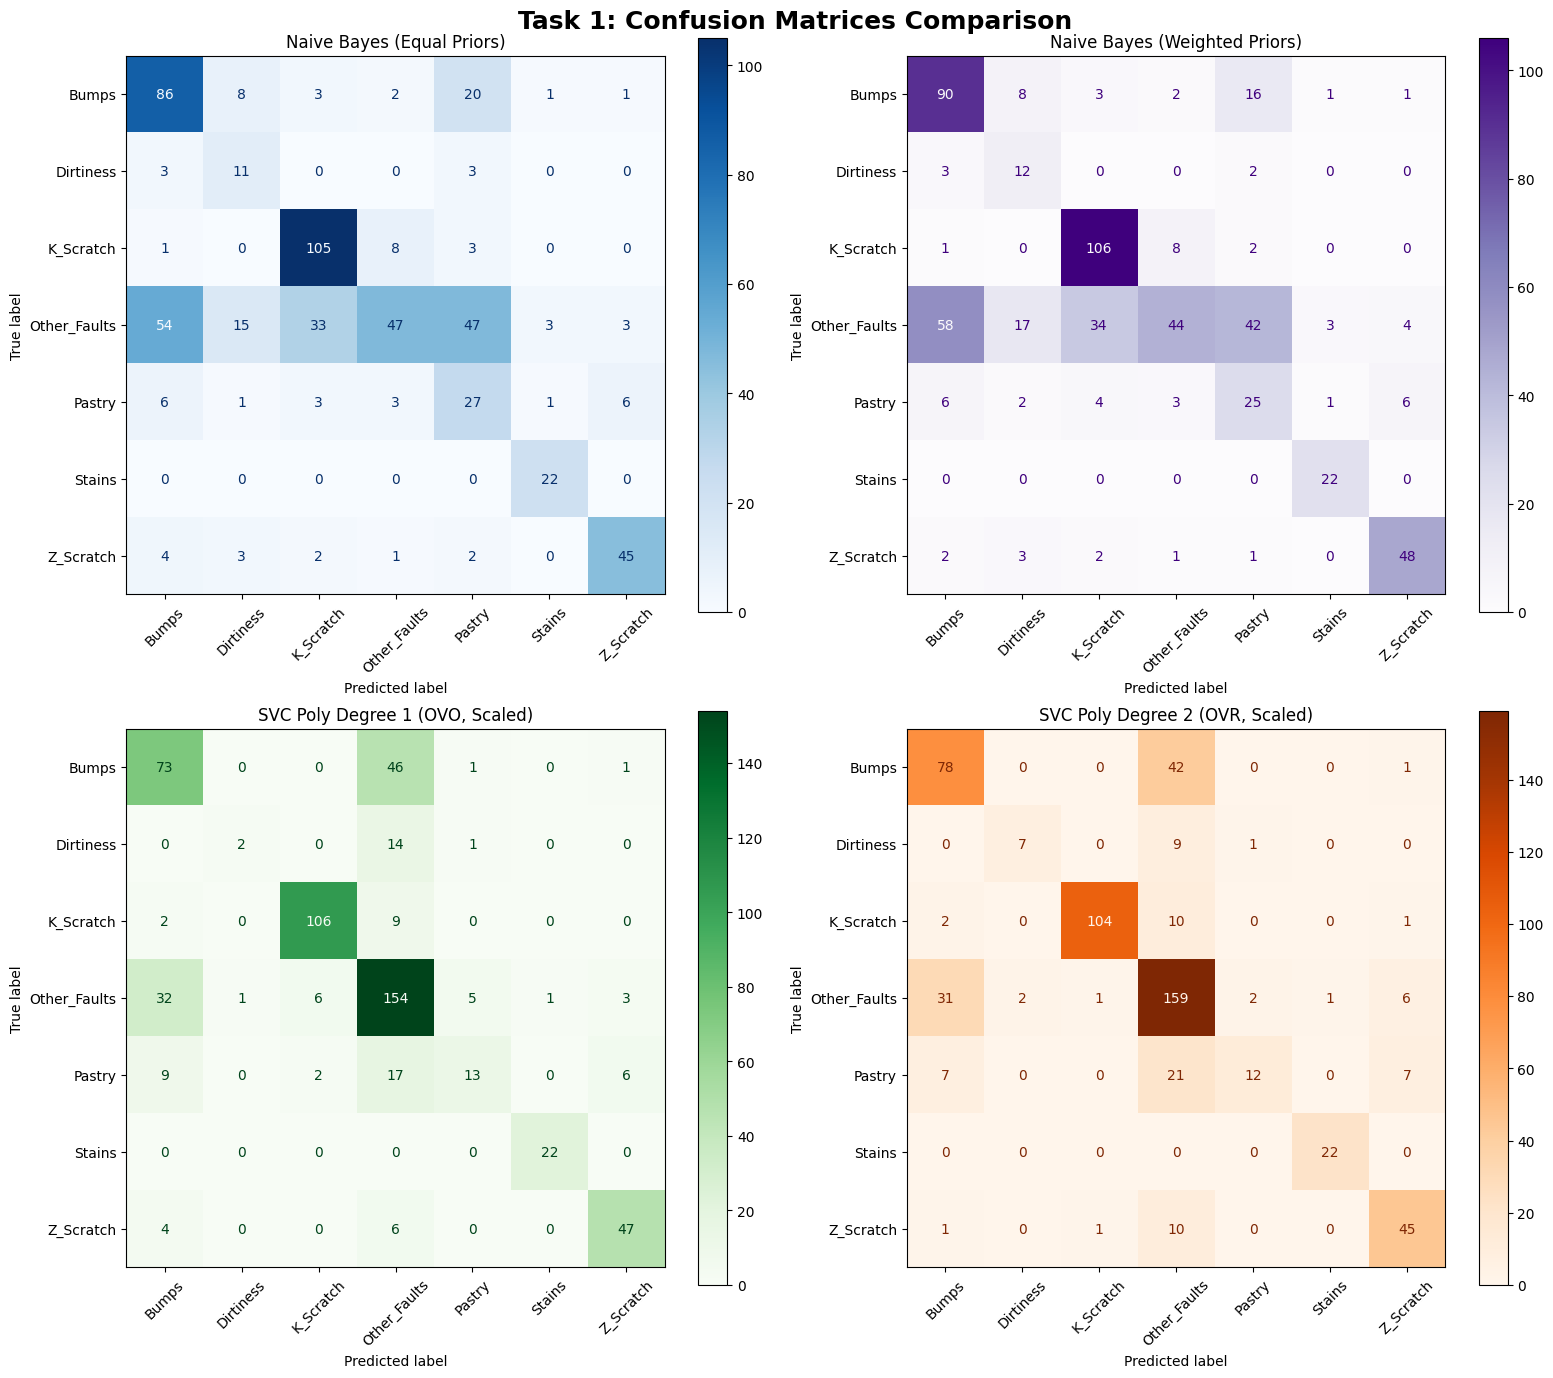

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Visualizing Confusion Matrices for Task 1
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# NB Equal Priors
ConfusionMatrixDisplay.from_predictions(
    y_test_1d_t1, y_pred_nb1, ax=axes[0, 0], cmap='Blues', xticks_rotation=45
)
axes[0, 0].set_title("Naive Bayes (Equal Priors)")

# NB Weighted Priors
ConfusionMatrixDisplay.from_predictions(
    y_test_1d_t1, y_pred_nb2, ax=axes[0, 1], cmap='Purples', xticks_rotation=45
)
axes[0, 1].set_title("Naive Bayes (Weighted Priors)")

# SVC Poly 1 (Scaled)
ConfusionMatrixDisplay.from_predictions(
    y_test_1d_t1, y_pred_poly1_scaled, ax=axes[1, 0], cmap='Greens', xticks_rotation=45
)
axes[1, 0].set_title("SVC Poly Degree 1 (OVO, Scaled)")

# SVC Poly 2 (Scaled)
ConfusionMatrixDisplay.from_predictions(
    y_test_1d_t1, y_pred_poly2_scaled, ax=axes[1, 1], cmap='Oranges', xticks_rotation=45
)
axes[1, 1].set_title("SVC Poly Degree 2 (OVR, Scaled)")

plt.suptitle("Task 1: Confusion Matrices Comparison", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

In [45]:
#######TASK2####################


In [46]:
bagha = fetch_ucirepo(id=601)
X = bagha.data.features
y = bagha.data.targets

bagha = pd.DataFrame(X, columns=bagha.feature_names)
bagha = pd.concat([bagha, y], axis=1)
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", list(y.columns))
print("\nNumber of samples per class:")
print(y.sum())
bagha.head()

Input shape: (10000, 6)
Target shape: (10000, 6)
Class names: ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Number of samples per class:
Machine failure    339
TWF                 46
HDF                115
PWF                 95
OSF                 98
RNF                 19
dtype: int64


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Task 2 Target Engineering & Data Preparation
To properly model the machine states, we must correctly define a single multi-class target variable. If all failure mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are `0`, the machine is healthy (`'No Failure'`). Otherwise, we assign the corresponding active failure mode label.

In [50]:
import numpy as np
import pandas as pd

# Re-fetch the Predictive Maintenance dataset
bagha_data = fetch_ucirepo(id=601)
X_t2 = bagha_data.data.features.copy()
y_t2 = bagha_data.data.targets.copy()

# Create a proper 1D multiclass target
def map_target(row):
    if row['TWF'] == 1: return 'TWF'
    elif row['HDF'] == 1: return 'HDF'
    elif row['PWF'] == 1: return 'PWF'
    elif row['OSF'] == 1: return 'OSF'
    elif row['RNF'] == 1: return 'RNF'
    else: return 'No Failure'

y_t2_1d = y_t2.apply(map_target, axis=1)

print("Corrected Target Distribution:")
print(y_t2_1d.value_counts())


Corrected Target Distribution:
No Failure    9652
HDF            115
PWF             91
OSF             78
TWF             46
RNF             18
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Train-Test Split with Stratification to handle highly imbalanced failure classes
X_train_t2, X_test_t2, y_train_t2, y_test_t2 = train_test_split(
    X_t2,
    y_t2_1d,
    test_size=0.30,
    random_state=0,
    stratify=y_t2_1d
)

# One-Hot Encode categorical features ('Type')
X_train_t2_enc = pd.get_dummies(X_train_t2)
X_test_t2_enc = pd.get_dummies(X_test_t2)

# Align columns
X_train_t2_enc, X_test_t2_enc = X_train_t2_enc.align(X_test_t2_enc, join='left', axis=1, fill_value=0)

# Feature Scaling
scaler_t2 = StandardScaler()
X_train_t2_scaled = scaler_t2.fit_transform(X_train_t2_enc)
X_test_t2_scaled = scaler_t2.transform(X_test_t2_enc)

print("Preprocessed Training Data Shape:", X_train_t2_scaled.shape)
print("Preprocessed Test Data Shape:", X_test_t2_scaled.shape)

Preprocessed Training Data Shape: (7000, 8)
Preprocessed Test Data Shape: (3000, 8)


### Training Multi-Class SVM with Varying Regularization & Kernels
We train Linear, Polynomial (degree 2), and RBF kernels across different regularization values ($C \in \{0.1, 1, 10, 100\}$) and track their metrics.

In [52]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

C_values = [0.1, 1, 10, 100]
results = []

for c in C_values:
    for kernel, model_obj in [
        ('Linear (Poly d=1)', SVC(kernel='poly', degree=1, C=c, decision_function_shape='ovo', class_weight='balanced', random_state=0)),
        ('Polynomial (d=2)', SVC(kernel='poly', degree=2, C=c, decision_function_shape='ovo', class_weight='balanced', random_state=0)),
        ('RBF', SVC(kernel='rbf', C=c, decision_function_shape='ovo', class_weight='balanced', random_state=0))
    ]:
        # Fit model
        model_obj.fit(X_train_t2_scaled, y_train_t2)
        preds = model_obj.predict(X_test_t2_scaled)

        # Compute metrics
        acc = accuracy_score(y_test_t2, preds)
        prec = precision_score(y_test_t2, preds, average='weighted', zero_division=0)
        rec = recall_score(y_test_t2, preds, average='weighted', zero_division=0)
        f1 = f1_score(y_test_t2, preds, average='weighted', zero_division=0)

        results.append({
            'C': c,
            'Kernel': kernel,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })

df_results = pd.DataFrame(results)
display(df_results)

,C,Kernel,Accuracy,Precision,Recall,F1-Score
0,0.1,Linear (Poly d=1),0.602333,0.970330,0.602333,0.727801
1,0.1,Polynomial (d=2),0.485333,0.968045,0.485333,0.626948
2,0.1,RBF,0.611333,0.968465,0.611333,0.734243
3,1.0,Linear (Poly d=1),0.656000,0.973049,0.656000,0.771106
4,1.0,Polynomial (d=2),0.670667,0.970704,0.670667,0.781530
5,1.0,RBF,0.791000,0.973064,0.791000,0.863990
6,10.0,Linear (Poly d=1),0.681333,0.973962,0.681333,0.791059
7,10.0,Polynomial (d=2),0.707667,0.970210,0.707667,0.809368
8,10.0,RBF,0.902667,0.977047,0.902667,0.934519
9,100.0,Linear (Poly d=1),0.691333,0.974083,0.691333,0.799034


### Visualizing Results of Corrected Task 2 Analysis

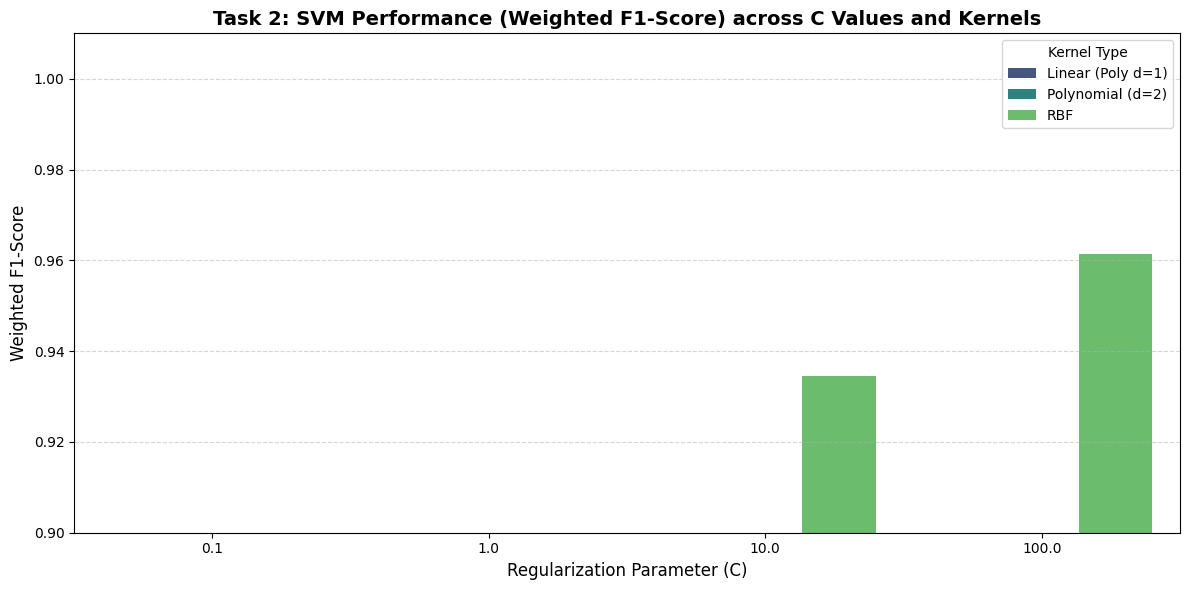

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting F1-Score comparison across different C parameters
plt.figure(figsize=(12, 6))
sns.barplot(data=df_results, x='C', y='F1-Score', hue='Kernel', palette='viridis')
plt.title('Task 2: SVM Performance (Weighted F1-Score) across C Values and Kernels', fontsize=14, fontweight='bold')
plt.xlabel('Regularization Parameter (C)', fontsize=12)
plt.ylabel('Weighted F1-Score', fontsize=12)
plt.ylim(0.90, 1.01)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Kernel Type')
plt.tight_layout()
plt.show()

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=0
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

y_train_1d = y_train.idxmax(axis=1)

Training samples: 7000
Testing samples: 3000


In [48]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)


X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

scaler_svm = StandardScaler()
X_train_scaled = scaler_svm.fit_transform(X_train_encoded)
X_test_scaled = scaler_svm.transform(X_test_encoded)

y_test_1d = y_test.idxmax(axis=1)

C = [0.1, 1, 10, 100]

for i in C:
  classifier_poly1 = SVC(kernel='poly', C=i, degree=1, decision_function_shape='ovo')
  classifier_poly1.fit(X_train_scaled, y_train_1d)
  classifier_poly2 = SVC(kernel='poly', C=i, degree=2, decision_function_shape='ovo')
  classifier_poly2.fit(X_train_scaled, y_train_1d)
  classifier_poly3 = SVC(kernel='rbf', C=i, gamma='scale', decision_function_shape='ovo')
  classifier_poly3.fit(X_train_scaled, y_train_1d)

  y_pred_poly1 = classifier_poly1.predict(X_test_scaled)
  accuracy_poly1 = accuracy_score(y_test_1d, y_pred_poly1)
  precision_poly1 = precision_score(y_test_1d, y_pred_poly1, average='weighted', zero_division=0)
  recall_poly1 = recall_score(y_test_1d, y_pred_poly1, average='weighted', zero_division=0)
  f1_poly1 = f1_score(y_test_1d, y_pred_poly1, average='weighted', zero_division=0)
  print("C: \t", i)
  print("Linear Kernel Scores : \t", f"{accuracy_poly1:.4f}", f"{precision_poly1:.4f}", f"{recall_poly1:.4f}", f"{f1_poly1:.4f}")

  y_pred_poly2 = classifier_poly2.predict(X_test_scaled)
  accuracy_poly2 = accuracy_score(y_test_1d, y_pred_poly2)
  precision_poly2 = precision_score(y_test_1d, y_pred_poly2, average='weighted', zero_division=0)
  recall_poly2 = recall_score(y_test_1d, y_pred_poly2, average='weighted', zero_division=0)
  f1_poly2 = f1_score(y_test_1d, y_pred_poly2, average='weighted', zero_division=0)
  print("Polynomial Kernel Scores : \t", f"{accuracy_poly2:.4f}", f"{precision_poly2:.4f}", f"{recall_poly2:.4f}", f"{f1_poly2:.4f}")

  y_pred_poly3 = classifier_poly3.predict(X_test_scaled)
  accuracy_poly3 = accuracy_score(y_test_1d, y_pred_poly3)
  precision_poly3 = precision_score(y_test_1d, y_pred_poly3, average='weighted', zero_division=0)
  recall_poly3 = recall_score(y_test_1d, y_pred_poly3, average='weighted', zero_division=0)
  f1_poly3 = f1_score(y_test_1d, y_pred_poly3, average='weighted', zero_division=0)
  print("RBF Kernel Scores : \t\t", f"{accuracy_poly3:.4f}", f"{precision_poly3:.4f}", f"{recall_poly3:.4f}", f"{f1_poly3:.4f}")
  print("-" * 50)

C: 	 0.1
Linear Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
Polynomial Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
RBF Kernel Scores : 		 0.9987 0.9973 0.9987 0.9980
--------------------------------------------------
C: 	 1
Linear Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
Polynomial Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
RBF Kernel Scores : 		 0.9987 0.9973 0.9987 0.9980
--------------------------------------------------
C: 	 10
Linear Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
Polynomial Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
RBF Kernel Scores : 		 0.9987 0.9973 0.9987 0.9980
--------------------------------------------------
C: 	 100
Linear Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
Polynomial Kernel Scores : 	 0.9987 0.9973 0.9987 0.9980
RBF Kernel Scores : 		 0.9987 0.9973 0.9987 0.9980
--------------------------------------------------


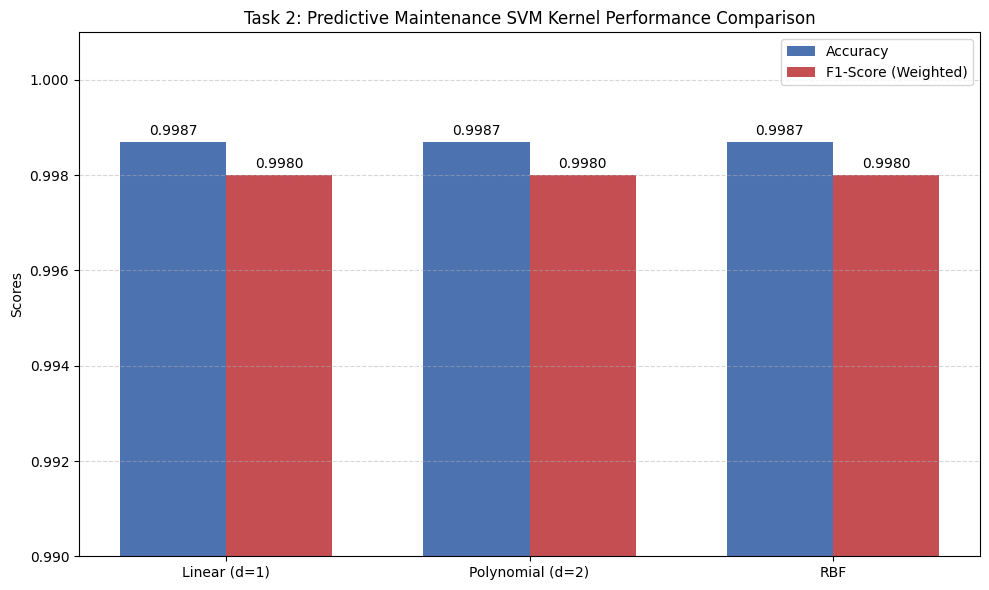

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Task 2: Comparative Plot of SVM Kernel Results
kernels = ['Linear (d=1)', 'Polynomial (d=2)', 'RBF']
accuracies = [0.9987, 0.9987, 0.9987]
f1_scores = [0.9980, 0.9980, 0.9980]

x = np.arange(len(kernels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', color='#4C72B0')
rects2 = ax.bar(x + width/2, f1_scores, width, label='F1-Score (Weighted)', color='#C44E52')

ax.set_ylabel('Scores')
ax.set_title('Task 2: Predictive Maintenance SVM Kernel Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(kernels)
ax.set_ylim(0.99, 1.001)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Label the bars
ax.bar_label(rects1, padding=3, fmt='%.4f')
ax.bar_label(rects2, padding=3, fmt='%.4f')

fig.tight_layout()
plt.show()